In [3]:
%load_ext autoreload
%autoreload 2

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from statsforecast.models import MSTL, AutoARIMA, AutoETS, AutoTheta

from wiki_forecast.baselines import seasonal_naive
from wiki_forecast.classical import prophet_model, statsforecast_model
from wiki_forecast.evaluation import backtest, summarize
from wiki_forecast.events import oktoberfest_holidays
from wiki_forecast.transforms import log_transformed

In [4]:
df = pd.read_parquet("../data/raw/oktoberfest.parquet")
s = df.set_index("date")["views"].asfreq("D")

N_FOLDS = 55
RESULTS_PATH = Path("../data/results/classical_oktoberfest.parquet")
RESULTS_PATH.parent.mkdir(parents=True, exist_ok=True)

In [5]:
holidays = oktoberfest_holidays()

models = {
    "snaive_364": seasonal_naive(364),
    "ets": log_transformed(statsforecast_model(lambda: AutoETS(season_length=7))),
    "arima": log_transformed(statsforecast_model(lambda: AutoARIMA(season_length=7))),
    "theta": log_transformed(statsforecast_model(lambda: AutoTheta(season_length=7))),
    "mstl": log_transformed(statsforecast_model(lambda: MSTL(season_length=[7, 364]))),
    "mstl_no_log": statsforecast_model(lambda: MSTL(season_length=[7, 364])),
    "prophet": log_transformed(prophet_model()),
    "prophet_events": log_transformed(prophet_model(holidays)),
}

In [6]:
def run_or_load(models: dict, path: Path, force: tuple = ()) -> pd.DataFrame:
    """Backtest only models that aren't saved yet (or are listed in `force`)."""
    saved = pd.read_parquet(path) if path.exists() else pd.DataFrame(columns=["model"])
    saved = saved[~saved["model"].isin(force)]
    done = set(saved["model"])

    new = []
    for name, forecaster in models.items():
        if name in done:
            print(f"{name:15s} loaded from cache")
        else:
            print(f"{name:15s} running backtest ...")
            new.append(backtest(s, forecaster, name, n_folds=N_FOLDS))

    results = pd.concat([saved, *new], ignore_index=True)
    results.to_parquet(path, index=False)
    return results


results = run_or_load(models, RESULTS_PATH)
results["year"] = results["date"].dt.year

Importing plotly failed. Interactive plots will not work.
17:40:53 - cmdstanpy - INFO - Chain [1] start processing


snaive_364      loaded from cache
ets             loaded from cache
arima           loaded from cache
theta           loaded from cache
mstl            loaded from cache
mstl_no_log     loaded from cache
prophet         running backtest ...


17:40:53 - cmdstanpy - INFO - Chain [1] done processing


prophet_events  running backtest ...


In [7]:
festival = results[results["date"].dt.month.isin([9, 10])]

display(summarize(results))
display(summarize(festival))
results.groupby("year").apply(summarize, include_groups=False)

,MAE,MASE
model,,
prophet_events,251.374954,0.548454
prophet,336.981980,0.737504
mstl,398.356955,0.872801
snaive_364,410.302597,0.900873
mstl_no_log,581.102725,1.265338
ets,858.277327,1.873703
theta,858.703251,1.874972
arima,1008.695015,2.193411


,MAE,MASE
model,,
prophet_events,732.601333,1.610310
prophet,1158.547964,2.551596
snaive_364,1252.052980,2.770621
mstl,1403.919737,3.101599
mstl_no_log,1886.309179,4.144932
ets,3576.710122,7.832982
theta,3582.441656,7.845910
arima,4381.684347,9.542764


MAE      MASE
year model                                
2022 prophet_events   591.563507  1.301296
     prophet          757.622775  1.671224
     mstl             760.685119  1.681187
     snaive_364       847.349650  1.861063
     mstl_no_log      966.409555  2.104940
     arima           1665.726297  3.621239
     theta           1671.912370  3.665458
     ets             1675.420576  3.672559
2023 prophet_events   233.069115  0.499272
     snaive_364       231.978082  0.499610
     prophet          327.822112  0.705651
     mstl             434.561602  0.937104
     mstl_no_log      561.996194  1.204140
     theta            860.700946  1.856933
     ets              865.323932  1.866476
     arima            973.118422  2.090653
2024 prophet_events   172.672774  0.373895
     prophet          232.881412  0.506133
     mstl             303.892652  0.661279
     snaive_364       310.478142  0.677659
     mstl_no_log      398.426376  0.865073
     theta            622.180243  1.353094
     ets              625.800258  1.360598
     arima            738.463864  1.599776
2025 prophet_events   266.570938  0.585866
     snaive_364       276.901370  0.607615
     prophet          359.447968  0.792028
     mstl             453.641629  1.001149
     mstl_no_log      782.956923  1.713593
     ets             1027.659850  2.247424
     theta           1041.917971  2.278750
     arima           1336.252158  2.913128
2026 prophet_events   189.225892  0.417317
     mstl             230.142356  0.512337
     prophet          247.588095  0.547756
     mstl_no_log      398.570395  0.883804
     theta            535.367656  1.191163
     ets              538.803875  1.198587
     arima            671.074509  1.488760
     snaive_364       702.056478  1.558314

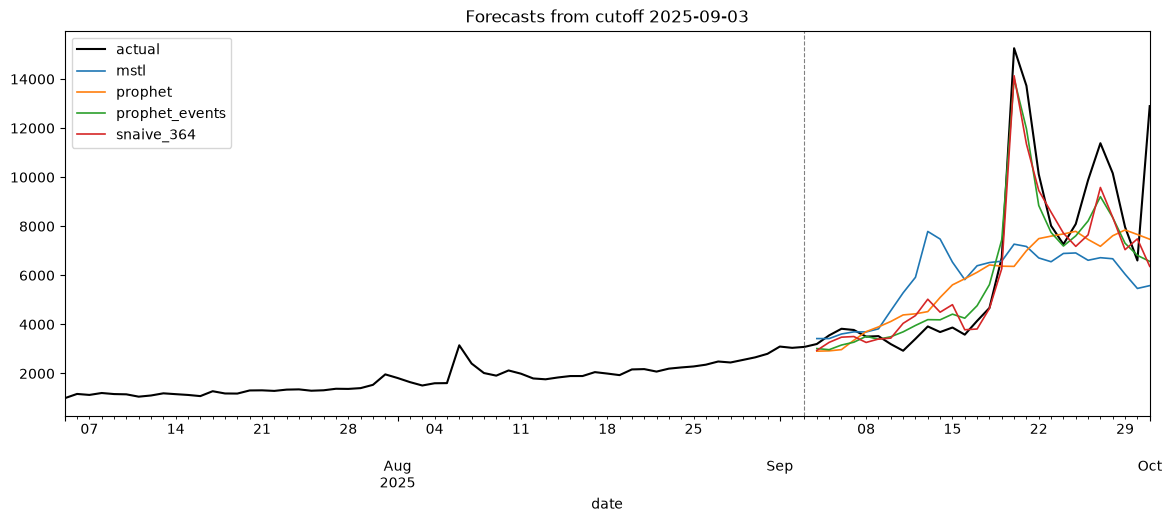

In [8]:
SHOW = ["snaive_364", "mstl", "prophet", "prophet_events"]

cutoffs = results["cutoff"].unique()
c = min(cutoffs, key=lambda x: abs(x - pd.Timestamp("2025-09-10")))
fold = results[(results["cutoff"] == c) & results["model"].isin(SHOW)]

fig, ax = plt.subplots(figsize=(14, 5))
s[c - pd.Timedelta(days=60) : fold["date"].max()].plot(
    ax=ax, color="black", lw=1.5, label="actual"
)
for name, g in fold.groupby("model"):
    ax.plot(g["date"], g["pred"], lw=1.2, label=name)
ax.axvline(c, color="gray", ls="--", lw=0.8)
ax.set_title(f"Forecasts from cutoff {c.date()}")
ax.legend()
plt.show()

## Findings

**Ranking (MAE, 55 folds, 28-day horizon, Aug 2022 – Oct 2026)**
- prophet_events 251 < prophet 337 < mstl 398 < snaive_364 410 < ets/theta ~858 < arima 1009
- Festival (Sep–Oct): prophet_events 733 vs. snaive_364 1,252 (~40% lower error).

**Key insights**
- Methods limited to weekly seasonality (ETS, Theta, ARIMA) can't see the yearly peak and lose
  to a simple "same day last year" baseline. ARIMA is also by far the slowest (~30 min).
- The log transform matters: MSTL with log has ~30% lower error than without.
- MSTL and plain Prophet learn an averaged yearly curve, which smears the sharp festival peak.
- Encoding the festival dates as known events (Prophet holidays) fixes the timing and wins in
  every year. The cancelled years (2020, 2021) are excluded, so they don't distort the effect.
- snaive_364 is precise in stable years but fragile after breaks (2022) and level shifts (2026).

**Limitations**
- The event feature is hand-crafted for this one article and doesn't scale automatically.
- Single series only; event window sizes were fixed in advance, not tuned.